In [1]:
import json
import os

import matplotlib            
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import os; print(os.environ.get("LD_LIBRARY_PATH"))

/opt/ohpc/pub/spack/develop/opt/spack/linux-rocky8-zen2/gcc-12.2.0/boost-1.85.0-qz55jyxhn3c3vfverplcn7u2obcdz3nz/lib:/opt/ohpc/pub/mpi/libfabric/1.19.0/lib:/opt/ohpc/pub/mpi/ucx-ohpc/1.15.0/lib:/opt/ohpc/pub/libs/hwloc/lib:/opt/ohpc/pub/mpi/openmpi4-gnu9/4.1.1/lib:/opt/ohpc/pub/compiler/gcc/9.4.0/lib64


In [2]:
results_folder = "output/screening_kappa_2.2_12_seeds"   
per_seed = pd.read_csv(os.path.join(results_folder, "per_seed.csv"))
print(len(per_seed), "runs")

576 runs


1. Hospital and ICU peaks compared with the first change day

In [3]:
rows = []
for number_to_save in per_seed["number_to_save"]:
    compartments = pd.read_csv(os.path.join(results_folder, f"{number_to_save}_comps_damping_compact_version.csv"), sep=" ")
    with open(os.path.join(results_folder, f"{number_to_save}_strategy.json")) as file:
        strategy = json.load(file)
    rows.append({"number_to_save": number_to_save,
                 "peak_day_severe": compartments.loc[compartments["Isev"].idxmax(), "t"] / 24,
                 "peak_day_critical": compartments.loc[compartments["Icri"].idxmax(), "t"] / 24,
                 "change_day_1": strategy["change_day_1"]})
peaks = pd.DataFrame(rows)
print("share of runs with the hospital peak before the first change day:",
      (peaks["peak_day_severe"] < peaks["change_day_1"]).mean().round(2))
print("share of runs with the ICU peak before the first change day:",
      (peaks["peak_day_critical"] < peaks["change_day_1"]).mean().round(2))
peaks[["peak_day_severe", "peak_day_critical", "change_day_1"]].describe().round(1)

share of runs with the hospital peak before the first change day: 0.38
share of runs with the ICU peak before the first change day: 0.0


,peak_day_severe,peak_day_critical,change_day_1
count,576.0,576.0,576.0
mean,32.5,43.2,31.1
std,2.4,2.1,4.2
min,27.7,38.3,25.0
25%,30.9,42.2,27.8
50%,32.9,43.6,30.0
75%,34.6,44.1,35.0
max,35.8,47.2,38.0


Problem: icu ding reagiert nicht auf die Interventionen (siehe testing_different_goals_analysis)

Example run: severe, critical and dead over time, change days as dashed lines

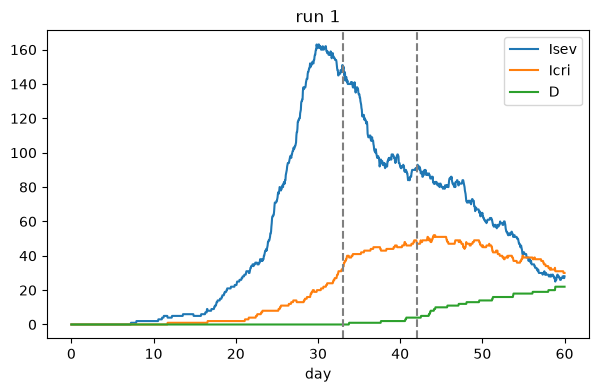

In [4]:
example = per_seed["number_to_save"].iloc[0]
compartments = pd.read_csv(os.path.join(results_folder, f"{example}_comps_damping_compact_version.csv"), sep=" ")
with open(os.path.join(results_folder, f"{example}_strategy.json")) as file:
    strategy = json.load(file)

figure, axis = plt.subplots(figsize=(7, 4))
for column in ["Isev", "Icri", "D"]:
    axis.plot(compartments["t"] / 24, compartments[column], label=column)
for change_day in (strategy["change_day_1"], strategy["change_day_2"]):
    axis.axvline(change_day, color="grey", linestyle="--")
axis.set_xlabel("day")
axis.set_title(f"run {example}")
axis.legend()
plt.show()

3. Presence: person-hours at home and at work after the first change day, compared with home office and f_I

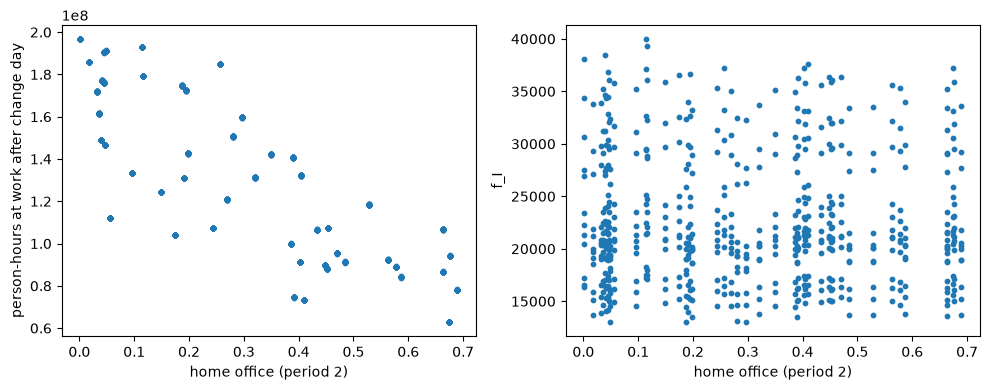

In [5]:
home, work = 0, 2   # Home, work
rows = []
for number_to_save in per_seed["number_to_save"]:
    presence = np.load(os.path.join(results_folder, f"{number_to_save}_presence.npy"))   # hour x location type x age group
    with open(os.path.join(results_folder, f"{number_to_save}_strategy.json")) as file:
        strategy = json.load(file)
    after_change = presence[strategy["change_day_1"] * 24:]
    rows.append({"number_to_save": number_to_save, "home_office_2": strategy["home_office_2"],
                 "home_hours": after_change[:, home].sum(), "work_hours": after_change[:, work].sum()})
presence_table = pd.DataFrame(rows).merge(per_seed[["number_to_save", "f_I"]], on="number_to_save")
presence_table[["home_office_2", "home_hours", "work_hours", "f_I"]].corr(method="spearman").round(2)

figure, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(presence_table["home_office_2"], presence_table["work_hours"], s=10)
axes[0].set_xlabel("home office (period 2)")
axes[0].set_ylabel("person-hours at work after change day")
axes[1].scatter(presence_table["home_office_2"], presence_table["f_I"], s=10)
axes[1].set_xlabel("home office (period 2)")
axes[1].set_ylabel("f_I")
plt.tight_layout()
plt.show()

               home_office_2  f_I_relative
home_office_2           1.00         -0.04
f_I_relative           -0.04          1.00


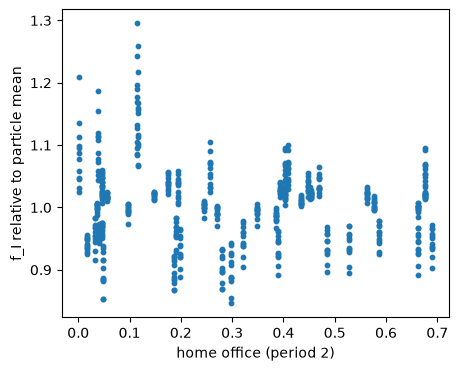

In [6]:
presence_table = presence_table.merge(per_seed[["number_to_save", "seed_index", "strategy"]], on="number_to_save")
presence_table["f_I_relative"] = presence_table["f_I"] / presence_table.groupby("seed_index")["f_I"].transform("mean")
print(presence_table[["home_office_2", "f_I_relative"]].corr(method="spearman").round(2))
figure, axis = plt.subplots(figsize=(5, 4))
axis.scatter(presence_table["home_office_2"], presence_table["f_I_relative"], s=10)
axis.set_xlabel("home office (period 2)")
axis.set_ylabel("f_I relative to particle mean")
plt.show()

Erkenntnis: home office macht keinen Unterschied


Warum?
- stecken die sich zu Hause an?
- wenige Ansteckungen allgemein auf der Arbeit

Idee:
Kontaktmatrix auf 0 setzen und schauen was passiert
Logger pro Ort 

In [11]:
input_folder = "input"
age_group_names = ["0-4", "5-15", "16-34", "35-59", "60-79", "80+"]

In [12]:
ages = pd.read_csv(os.path.join(input_folder, "persons_scaled.csv"), usecols=["age"])["age"].to_numpy()
age_group_of_person = np.digitize(ages, [5, 16, 35, 60, 80])

new infections per age group after the first change day, for every run

In [13]:
rows = []
for number_to_save in per_seed["number_to_save"]:
    infection_paths = pd.read_csv(os.path.join(results_folder, f"{number_to_save}_infection_paths_damping.txt"), sep=r"\s+")
    with open(os.path.join(results_folder, f"{number_to_save}_strategy.json")) as file:
        strategy = json.load(file)
    infection_hour = infection_paths["S"].to_numpy()
    age_group = age_group_of_person[infection_paths["Agent_id"].to_numpy()]
    after_change = (infection_hour >= strategy["change_day_1"] * 24) & (infection_hour < 60 * 24)
    counts = np.bincount(age_group[after_change], minlength=len(age_group_names))
    rows.append({"number_to_save": number_to_save, "home_office_2": strategy["home_office_2"],
                 **dict(zip(age_group_names, counts))})
age_table = pd.DataFrame(rows).merge(per_seed[["number_to_save", "seed_index", "strategy"]], on="number_to_save")
age_table.head()


,number_to_save,home_office_2,0-4,5-15,16-34,35-59,60-79,80+,seed_index,strategy
0,1,0.469215,266,502,1625,2112,291,48,19,0
1,2,0.469215,164,378,955,1352,184,23,23,0
2,3,0.469215,222,436,1428,1776,270,34,28,0
3,4,0.469215,74,203,499,725,102,20,35,0
4,5,0.469215,163,337,949,1254,206,28,41,0


relative to the particle mean (removes the particle effect, like for f_I) and correlation with home office

In [14]:
for name in age_group_names:
    age_table[f"{name}_relative"] = age_table[name] / age_table.groupby("seed_index")[name].transform("mean")
correlation = {name: age_table["home_office_2"].corr(age_table[f"{name}_relative"], method="spearman")
               for name in age_group_names}
print("Spearman correlation home office (period 2) vs. infections of the age group:")
print(pd.Series(correlation).round(2))


Spearman correlation home office (period 2) vs. infections of the age group:
0-4     -0.07
5-15    -0.08
16-34   -0.06
35-59   -0.07
60-79    0.01
80+      0.01
dtype: float64


share of each age group among the infections after the change day: little vs. much home office

       home office < 0.2  home office > 0.5
0-4                0.055              0.058
5-15               0.122              0.127
16-34              0.317              0.314
35-59              0.451              0.439
60-79              0.049              0.056
80+                0.006              0.007


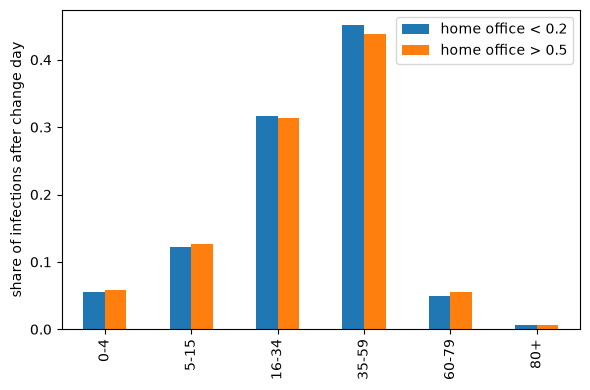

In [15]:
total = age_table[age_group_names].sum(axis=1)
little = age_table["home_office_2"] < 0.2
much = age_table["home_office_2"] > 0.5
shares = pd.DataFrame({"home office < 0.2": age_table.loc[little, age_group_names].div(total[little], axis=0).mean(),
                       "home office > 0.5": age_table.loc[much, age_group_names].div(total[much], axis=0).mean()})
print(shares.round(3))
axis = shares.plot.bar(figsize=(6, 4))
axis.set_ylabel("share of infections after change day")
plt.tight_layout()
plt.show()

In [16]:
population = np.bincount(age_group_of_person, minlength=len(age_group_names))
rates = pd.DataFrame({"home office < 0.2": age_table.loc[little, age_group_names].mean() / population,
                      "home office > 0.5": age_table.loc[much, age_group_names].mean() / population})
print((rates * 100).round(2))   # infections after the change day per 100 persons

       home office < 0.2  home office > 0.5
0-4                 0.17               0.17
5-15                0.23               0.23
16-34               0.32               0.26
35-59               0.28               0.22
60-79               0.05               0.05
80+                 0.03               0.03


In [17]:

extremes_folder = "/storage/users/anne_sophie/extremes"
extremes = pd.read_csv(os.path.join(extremes_folder, "extremes_per_seed.csv"))
rows = []
for _, run in extremes.iterrows():
    infection_paths = pd.read_csv(os.path.join(extremes_folder, f"{run['number_to_save']}_infection_paths_damping.txt"), sep=r"\s+")
    infection_hour = infection_paths["S"].to_numpy()
    age_group = age_group_of_person[infection_paths["Agent_id"].to_numpy()]
    after_change = (infection_hour >= 25 * 24) & (infection_hour < 60 * 24)      # all extreme strategies start after day 25
    counts = np.bincount(age_group[after_change], minlength=len(age_group_names))
    rows.append({"strategy": run["strategy"], "seed_index": run["seed_index"], **dict(zip(age_group_names, counts))})
extremes_age = pd.DataFrame(rows)
rates = extremes_age.groupby("strategy")[age_group_names].mean() / population * 100
print(rates.round(3))

                    0-4   5-15  16-34  35-59  60-79    80+
strategy                                                  
all_maximal       0.214  0.276  0.224  0.175  0.057  0.034
closures_only     0.235  0.299  0.393  0.328  0.069  0.040
home_office_only  0.433  0.718  0.787  0.624  0.179  0.112
no_measures       0.468  0.848  1.396  1.226  0.185  0.108
tests_only        0.174  0.175  0.103  0.090  0.027  0.013
